In [ ]:
# load all the modules

import pandas as pd #data manipulation and analysis
import matplotlib.pyplot as plt #plotting and visualization
import seaborn as sns #good looking and complex visualizations
import sqlite3 #managing smaller SQL files
import requests #APIs, scrapping, etc
import os #interaction with operation system
from dotenv import load_dotenv # loads cofigs. from a hidden file

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#reads and saves table from url to tables (simple webscraping)
url = "https://dlai-lc-dag.s3.us-east-2.amazonaws.com/restaurant_inspections.html"
tables = pd.read_html(url)
if len(tables) > 0:
    print("Downloaded tables successfully. Found a total of", len(tables), "tables.")
else:
    print("Could not find any tables")

Downloaded tables successfully. Found a total of 1 tables.


In [ ]:
inspections = tables[0]
inspections.head(2)

,CAMIS,DBA,BORO,BUILDING,STREET,ZIPCODE,PHONE,CUISINE DESCRIPTION,INSPECTION DATE,ACTION,...,RECORD DATE,INSPECTION TYPE,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
0,50060054,SBARRO,Brooklyn,2509,FLATBUSH AVENUE,11234.0,7182583869,Pizza,07/01/2024,Violations were cited in the following area(s).,...,02/20/2025,Cycle Inspection / Initial Inspection,40.609174,-73.921785,318.0,46.0,69800.0,3326830.0,3.084700e+09,BK45
1,41305916,DUNKIN,Queens,13504,JAMAICA AVENUE,11418.0,7182629567,Donuts,07/01/2024,Violations were cited in the following area(s).,...,02/20/2025,Cycle Inspection / Initial Inspection,40.702394,-73.817640,409.0,29.0,14202.0,4442218.0,4.093420e+09,QN54


In [ ]:
#data scraper via API
#loads data in chunks and combine them into a bigger table

url_info = "https://2eraiuh.dlai.link/api/business_info"

errors_ratings = []
load_dotenv()
API_KEY = os.getenv('API_KEY')
if not API_KEY:
    raise ValueError("API_KEY not found! Please create a .env file with your key.")

#setting of the request
params = {
    "api_key": API_KEY,
    "limit": 1000,
    "offset":0
}

ratings_dataframes = []

#pagination
for i in range(35):
    params["offset"] = i * 1000
    response = requests.get(url_info, params=params)

    if response.status_code == 200:
        response_data = response.json()["data"]
        partial_df = pd.DataFrame(response_data)
        ratings_dataframes.append(partial_df)
    else:
        print("Failed to retrieve the general information data")
        errors_ratings.append(i)
        if "error" in response.json().keys():
            print(response.json()["error"])

ratings_df = pd.concat(ratings_dataframes, ignore_index=True)

if len(errors_ratings) == 0:
    print("Ratings data retrieved successfully")

Ratings data retrieved successfully


In [ ]:
ratings_df.head(2)

,address,name,place_id,price_level,rating,total_reviews,types
0,"114 E Burnside Ave, Bronx, NY 10453, United St...",San Lucas #2 Mexican Food,ChIJB9BYbbj1wokRJ24ZgjuZplM,$$,3.6,47.0,"restaurant, point_of_interest, food, establish..."
1,"238 Thompson St, New York, NY 10012, United St...",The Catholic Center at NYU,ChIJPWJOEJFZwokRX9iE7AMRQ0A,None,4.7,14.0,"church, place_of_worship, point_of_interest, e..."


In [ ]:
#cleaning and adjusting data from first table

inspections_clean = inspections.copy()

special_char_pattern = r"[^A-Z0-9 ]"

inspections_clean["DBA"] = inspections_clean["DBA"].str.replace(
                            special_char_pattern, "", regex=True)

inspections_clean["DBA"] = inspections_clean["DBA"].str.replace("  "," ")

inspections_clean["INSPECTION DATE"] = pd.to_datetime(inspections_clean["INSPECTION DATE"])

inspections_clean["GRADE DATE"] = pd.to_datetime(inspections_clean["GRADE DATE"])

inspections_clean["RECORD DATE"] = pd.to_datetime(inspections_clean["RECORD DATE"])

inspections_clean["INSPECTION TYPE"] = inspections_clean["INSPECTION TYPE"].str.split('/').str[1].str.strip()

long_names = ["AVENUE", "STREET", "ROAD", "BOULEVARD", "DRIVE", "LANE", "COURT", "PLACE"]
abbreviations = ["AVE", "ST", "RD", "BLVD", "DR", "LN", "CT", "PL"]

for i in range(len(long_names)):
    inspections_clean["STREET"] = inspections_clean['STREET'].str.replace(long_names[i], abbreviations[i])

inspections_clean.columns = inspections_clean.columns.str.replace(" ", "_")

In [ ]:
inspections_clean.dtypes

,0
CAMIS,int64
DBA,object
BORO,object
BUILDING,object
STREET,object
ZIPCODE,float64
PHONE,object
CUISINE_DESCRIPTION,object
INSPECTION_DATE,datetime64[ns]
ACTION,object


In [ ]:
#cleaning and adjusting data from second table

ratings_clean = ratings_df.copy()

ratings_clean = ratings_clean.drop_duplicates()

ratings_clean["name"] = ratings_clean["name"].str.upper()

ratings_clean["name"] = ratings_clean["name"].str.replace(
                            special_char_pattern, "", regex=True)

ratings_clean["name"] = ratings_clean["name"].str.replace("  ", " ")

In [ ]:
possible_price_level = ["$$$$$", "$$$$", "$$$", "$$", "$", " - No ratings yet"]

# replace $ with numbers in the price level column price level
for i in range(len(possible_price_level)):
    ratings_clean["price_level"] = ratings_clean["price_level"].str.replace(possible_price_level[i], str(5-i))

# extract zip codes
ratings_clean["zip_code"] = ratings_clean["address"].str.extract(r"(\d{5})")

In [ ]:
ratings_clean.head(10)

,address,name,place_id,price_level,rating,total_reviews,types,zip_code
0,"114 E Burnside Ave, Bronx, NY 10453, United St...",SAN LUCAS 2 MEXICAN FOOD,ChIJB9BYbbj1wokRJ24ZgjuZplM,2,3.6,47.0,"restaurant, point_of_interest, food, establish...",10453
1,"238 Thompson St, New York, NY 10012, United St...",THE CATHOLIC CENTER AT NYU,ChIJPWJOEJFZwokRX9iE7AMRQ0A,None,4.7,14.0,"church, place_of_worship, point_of_interest, e...",10012
2,"150-29 Northern Blvd, Flushing, NY 11354, Unit...",HANYANG CHICKEN FLUSHING,ChIJPy7oSkVhwokRiCgXhYA7KBo,2,4.4,87.0,"restaurant, food, point_of_interest, establish...",11354
3,"1608 Marcus Ave, New Hyde Park, NY 11040, Unit...",SMASHBURGER,ChIJ736a6CaIwokREbLrV-7wUVc,2,4.4,1485.0,"store, restaurant, food, point_of_interest, es...",11040
4,"194 Columbia St, Brooklyn, NY 11231, United St...",POPPYS HQ,ChIJM9HzYV1bwokRefjhDzqvCdA,None,5.0,3.0,"point_of_interest, establishment",11231
5,"Queens, NY 11361, United States",BELL BLNORTHERN BL,ChIJg6wM5-BhwokRkaCuShf8ah8,None,0.0,0.0,"transit_station, point_of_interest, establishment",11361
6,"353 W 14th St, New York, NY 10014, United States",GRAPE LEAF NEW YORK,ChIJG3auoL9ZwokR5h3Rz2KYqd8,None,3.0,2.0,"restaurant, food, point_of_interest, establish...",10014
7,"303 Lexington Ave, New York, NY 10016, United ...",TAKE CARE BISTRO,ChIJx5JD785ZwokRbqE_vi7K1wg,None,4.7,78.0,"restaurant, food, point_of_interest, establish...",10016
8,"445 Park Ave 9th floor, New York, NY 10022, Un...",HARDEE BROTHERS,ChIJv6c6L-VYwokR2wBQjX5jLqg,None,0.0,0.0,"finance, point_of_interest, establishment",10022
9,"31-10 47th St, Long Island City, NY 11103, Uni...",ROOTS NYC,ChIJ-2sxIBZfwokRxYSSPgv3GUQ,None,5.0,10.0,"church, place_of_worship, point_of_interest, e...",11103


In [ ]:
print("Restaurant data types:")
print(ratings_clean.dtypes, "\n")

Restaurant data types:
address           object
name              object
place_id          object
price_level       object
rating           float64
total_reviews    float64
types             object
zip_code          object
dtype: object 



In [ ]:
ratings_clean["price_level"] = ratings_clean['price_level'].astype("Int64")
ratings_clean["zip_code"] = ratings_clean['zip_code'].astype("Int64")

In [ ]:
print("General information data types:")
print(ratings_clean.dtypes)

General information data types:
address           object
name              object
place_id          object
price_level        Int64
rating           float64
total_reviews    float64
types             object
zip_code           Int64
dtype: object


In [ ]:
# moves inspection and ratings to a file (from RAM)
connection = sqlite3.connect("restaurant_data.db")

inspections_clean.to_sql("inspections", connection, if_exists="replace", index=False)
ratings_clean.to_sql("ratings", connection, if_exists="replace", index=False)
connection.close()
print("DataFrames have been saved to the SQLite database 'restaurant_data.db'")

DataFrames have been saved to the SQLite database 'restaurant_data.db'


In [ ]:
connection = sqlite3.connect("restaurant_data.db")

query = """
SELECT *
FROM ratings
LIMIT 1
"""
pd.read_sql_query(query, connection)

,address,name,place_id,price_level,rating,total_reviews,types,zip_code
0,"114 E Burnside Ave, Bronx, NY 10453, United St...",SAN LUCAS 2 MEXICAN FOOD,ChIJB9BYbbj1wokRJ24ZgjuZplM,2,3.6,47.0,"restaurant, point_of_interest, food, establish...",10453


In [ ]:
query_score_by_type = """
SELECT CUISINE_DESCRIPTION,
       COUNT(CAMIS) as total_inspections,
       AVG(SCORE) as avg_score
FROM inspections
GROUP BY CUISINE_DESCRIPTION
ORDER BY avg_score ASC
"""

scores_by_cuisine_df = pd.read_sql_query(query_score_by_type, connection)

In [ ]:
scores_by_cuisine_df.head()

,CUISINE_DESCRIPTION,total_inspections,avg_score
0,Portuguese,3,7.333333
1,Cajun,5,7.600000
2,Creole/Cajun,9,9.555556
3,Nuts/Confectionary,2,12.000000
4,Armenian,9,12.333333


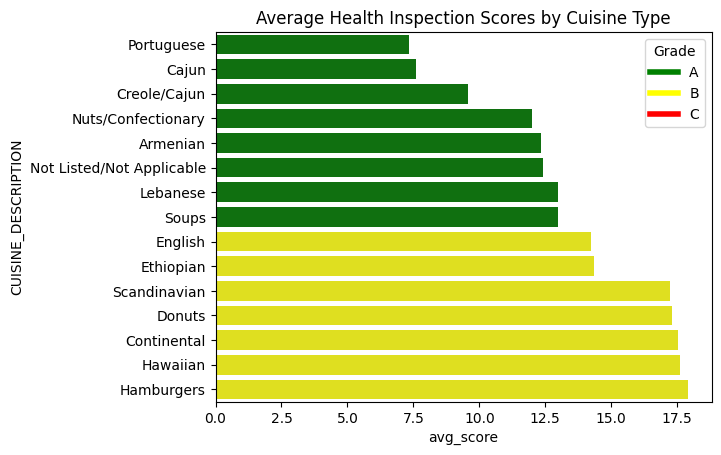

In [ ]:
def assign_grade(score):
    if score < 14:
        return "A"
    elif 14 <= score <= 27:
        return "B"
    else:
        return "C"

scores_by_cuisine_df["grade"] = scores_by_cuisine_df["avg_score"].apply(assign_grade)

palette = {"A": "green", "B": "yellow", "C": "red"}

sns.barplot(data=scores_by_cuisine_df.head(15), x="avg_score", y="CUISINE_DESCRIPTION", hue="grade", palette=palette, dodge=False)
plt.title("Average Health Inspection Scores by Cuisine Type")

handles = [plt.Line2D([0], [0], color=color, lw=4) for color in palette.values()]
labels = palette.keys()
plt.legend(handles, labels, title="Grade")

plt.show()

In [ ]:
query_score_by_price_level = """
SELECT DISTINCT inspections.DBA,
                inspections.SCORE,
                inspections.INSPECTION_DATE,
                ratings.price_level,
                ratings.rating
FROM inspections JOIN ratings
ON inspections.DBA = ratings.name AND inspections.ZIPCODE = ratings.zip_code
WHERE ratings.price_level IS NOT NULL
ORDER BY inspections.SCORE DESC
"""

score_by_price_level_df = pd.read_sql_query(query_score_by_price_level, connection)

In [ ]:
score_by_price_level_df.head()

,DBA,SCORE,INSPECTION_DATE,price_level,rating
0,FUSION EAST,131.0,2024-09-19 00:00:00,2,3.8
1,HALAL MUNCHIES,122.0,2024-10-07 00:00:00,1,4.6
2,PANNA II GARDEN INDIAN RESTAURANT,121.0,2024-07-24 00:00:00,1,3.5
3,CHEF 28,118.0,2024-08-01 00:00:00,2,3.9
4,HABANA OUTPOST,113.0,2024-09-25 00:00:00,1,4.6


Text(0.5, 1.0, 'Health Inspection Scores by Price Level')

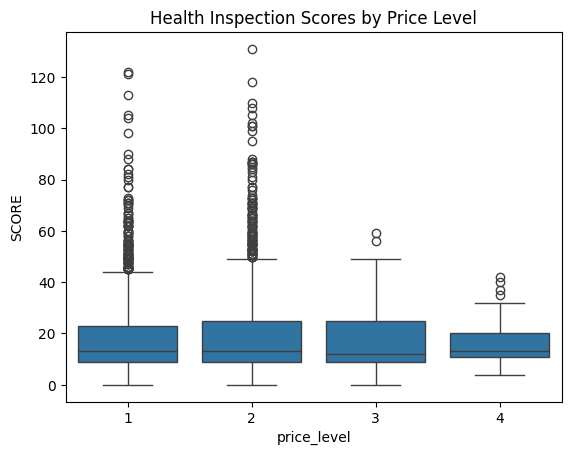

In [ ]:
sns.boxplot(data=score_by_price_level_df, x="price_level", y="SCORE")
plt.title("Health Inspection Scores by Price Level")

In [ ]:
query_success_rate = """
SELECT INSPECTION_TYPE,
       COUNT(*) as total_inspections,
       AVG(CASE WHEN SCORE <= 13 THEN 1 ELSE 0 END) * 100 as pass_rate,
       AVG(SCORE) as avg_score
FROM inspections
WHERE SCORE IS NOT NULL
GROUP BY INSPECTION_TYPE
ORDER BY pass_rate DESC
"""

success_rate_df = pd.read_sql_query(query_success_rate, connection)

In [ ]:
success_rate_df.head()

,INSPECTION_TYPE,total_inspections,pass_rate,avg_score
0,Reopening Inspection,736,58.152174,16.722826
1,Re-inspection,13456,37.225030,27.152125
2,Initial Inspection,33171,34.237738,27.753037
3,Second Compliance Inspection,54,29.629630,30.648148
4,Compliance Inspection,643,17.729393,35.023328


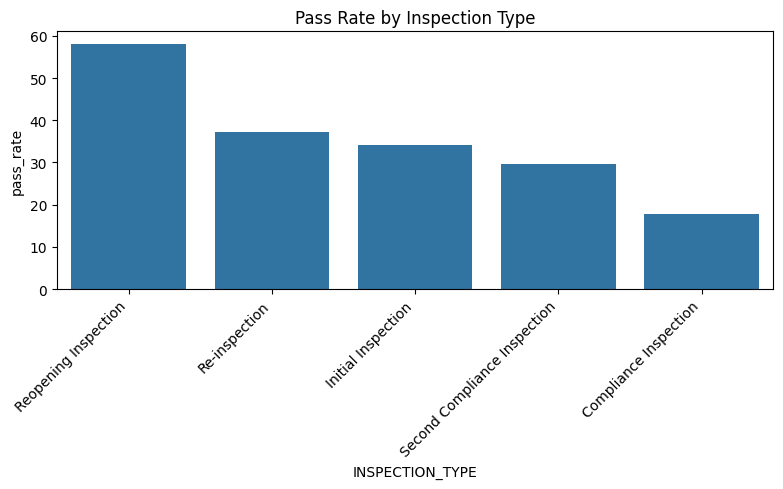

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=success_rate_df, x="INSPECTION_TYPE", y="pass_rate")
plt.xticks(rotation=45, ha="right")
plt.title("Pass Rate by Inspection Type")
plt.tight_layout()

In [ ]:
connection.close()